### Get data

In [87]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [88]:
dist_gray = 2.35
dist_red = 2.06

holes_gray = 15
holes_red = 20

In [89]:
path1 = '/home/gea/Desktop/notebooks/Notebooks/School/Lab/First_semester /temperature/barrarossa.txt'
path2 = '/home/gea/Desktop/notebooks/Notebooks/School/Lab/First_semester /temperature/barragrigia.txt'

df_red = pd.read_csv(path1, header=None, comment='#',
                   names=['no1', 'no2', 'time', 'temp'])  # accidentaly, i made this one in csv, so don't put delim_whitespace

df_gray = pd.read_csv(path2, header=None, delim_whitespace=True, comment='#',
                   names=['no1', 'no2', 'time', 'temp'])

In [90]:
df_red.head()

,no1,no2,time,temp
0,0.249,22.23,0.500,31.53
1,0.750,22.33,1.001,31.97
2,1.251,22.13,1.502,32.41
3,1.752,22.23,2.002,32.74
4,2.252,22.23,2.503,32.85


### Find temperatures of convergence

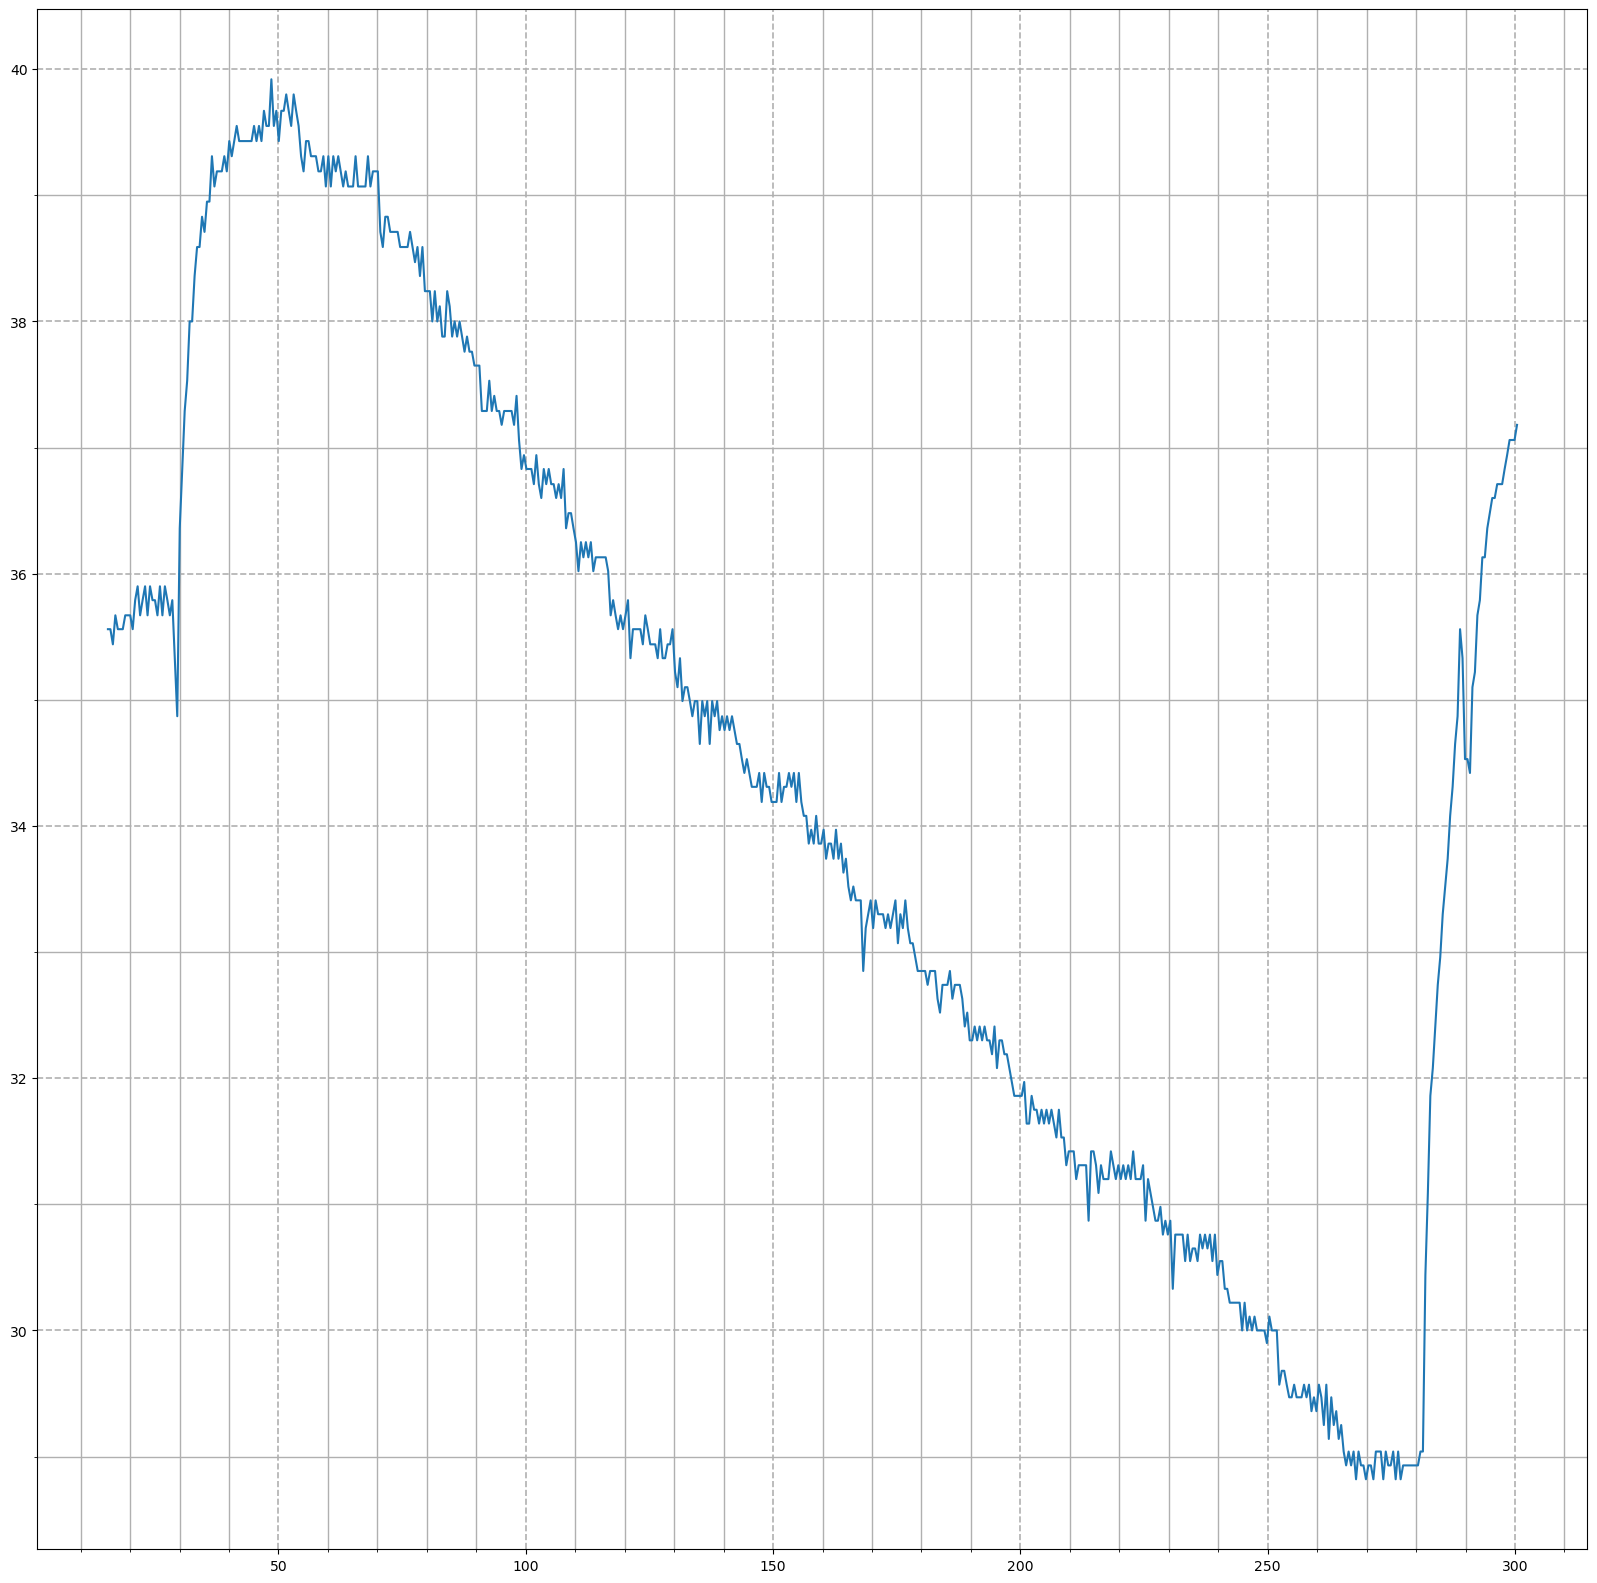

In [91]:
fig, ax = plt.subplots(figsize=(20,20))
ax.plot(df_red.time[30:600], df_red.temp[30:600])

import matplotlib.ticker as ticker
ax.minorticks_on()
ax.xaxis.set_minor_locator(ticker.MultipleLocator(10))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))   # if want more intermediate lines, put smaller number
ax.grid(True, which='minor', linestyle='-', linewidth=1)
ax.grid(True, which='major', linestyle='--', linewidth=1.2)
plt.show()

#### Plot it

##### Obtain mean

actually, would be fine to just note the value while doing the experiment, or the time it converged at, and then just use that value to write a python array  

In [92]:
df_gray[530::]

,no1,no2,time,temp
530,265.618,21.82,265.868,31.31
531,266.119,21.61,266.369,31.31
532,266.620,21.71,266.869,31.31
533,267.120,21.82,267.370,31.09
534,267.621,21.82,267.871,31.31
535,268.122,21.82,268.372,31.20


In [93]:
df_gray[92:112].mean()[3]

/tmp/ipykernel_9322/3225155923.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df_gray[92:112].mean()[3]


46.956

In [94]:
start_gray=[92, 112, 141, 185, 212, 249, 273, 301, 321, 351, 383, 409, 445, 476, 505, 535]
start_red=[72, 115, 139, 157, 177, 195, 214, 232, 258, 283, 310, 328, 352, 375, 393, 416, 448, 477, 502, 526, 561]



In [95]:
temps_gray=[]
for num in range(15):
    mean = df_gray[start_gray[num]:start_gray[num+1]].mean()[3]
    print(f'Buco numero {num}: temperatura {mean}')
    temps_gray.append(mean)


temps_red=[]
for num in range(20):
    mean = df_red[start_red[num]:start_red[num+1]].mean()[3]
    print(f'Buco numero {num}: temperatura {mean}')
    temps_red.append(mean)



Buco numero 0: temperatura 46.956
Buco numero 1: temperatura 45.75310344827586
Buco numero 2: temperatura 44.10909090909092
Buco numero 3: temperatura 42.573703703703714
Buco numero 4: temperatura 41.34324324324325
Buco numero 5: temperatura 40.2525
Buco numero 6: temperatura 39.143571428571434
Buco numero 7: temperatura 38.089000000000006
Buco numero 8: temperatura 36.96399999999999
Buco numero 9: temperatura 35.755625
Buco numero 10: temperatura 34.699615384615385
Buco numero 11: temperatura 33.758611111111115
Buco numero 12: temperatura 32.91161290322581
Buco numero 13: temperatura 32.06103448275862
Buco numero 14: temperatura 31.321
Buco numero 0: temperatura 39.45860465116279
Buco numero 1: temperatura 39.165
Buco numero 2: temperatura 38.670555555555566
Buco numero 3: temperatura 38.0415
Buco numero 4: temperatura 37.38388888888889
Buco numero 5: temperatura 36.81
Buco numero 6: temperatura 36.24777777777777
Buco numero 7: temperatura 35.55346153846154
Buco numero 8: temperatura 

/tmp/ipykernel_9322/123665678.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  mean = df_gray[start_gray[num]:start_gray[num+1]].mean()[3]
/tmp/ipykernel_9322/123665678.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  mean = df_red[start_red[num]:start_red[num+1]].mean()[3]


In [96]:
temps_gray

[46.956,
 45.75310344827586,
 44.10909090909092,
 42.573703703703714,
 41.34324324324325,
 40.2525,
 39.143571428571434,
 38.089000000000006,
 36.96399999999999,
 35.755625,
 34.699615384615385,
 33.758611111111115,
 32.91161290322581,
 32.06103448275862,
 31.321]

In [97]:
x1 = np.arange(0, holes_gray)
x1 = x1*dist_gray

x2 = np.arange(0, holes_red)
x2 = x2*dist_red


### Plot

what i have:  

temps: temperatures at all holes

In [98]:
def line(x, m, q):
    """Modello lineare di fit."""
    return m * x + q

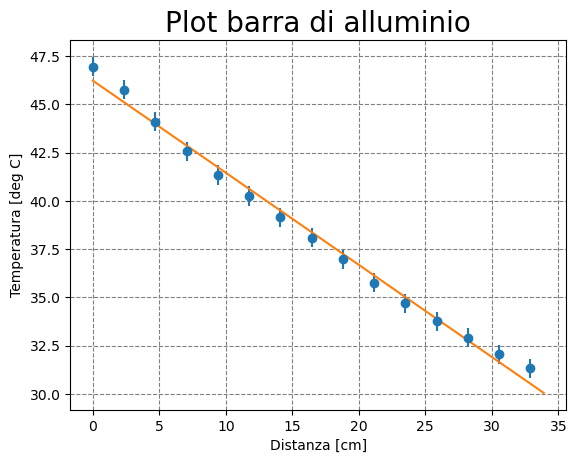

In [99]:
from scipy.optimize import curve_fit

plt.errorbar(x1, temps_gray, 0.5, fmt='o')

popt, pcov = curve_fit(line, x1, temps_gray)
m_hat, q_hat = popt
sigma_m, sigma_q = np.sqrt(pcov.diagonal())

x = np.linspace(0., max(x1)+1, 100)
plt.plot(x, line(x, m_hat, q_hat))

plt.grid(which='both', ls='dashed', color='gray')

plt.xlabel('Distanza [cm]')
plt.ylabel('Temperatura [deg C]')
plt.title('Plot barra di alluminio', fontsize=20)

plt.show()

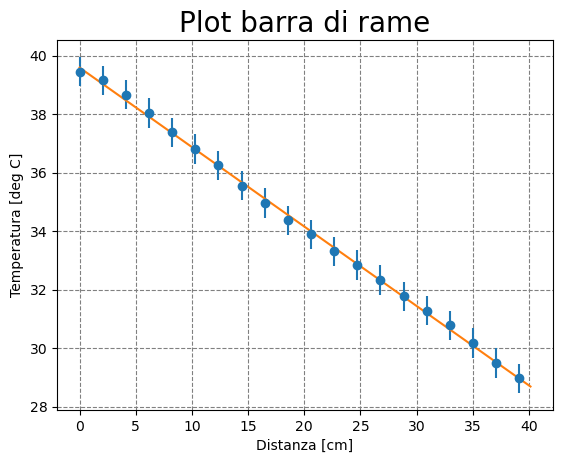

In [100]:
plt.errorbar(x2, temps_red, 0.5, fmt='o')

popt, pcov = curve_fit(line, x2, temps_red)
m_hat, q_hat = popt
sigma_m, sigma_q = np.sqrt(pcov.diagonal())

x = np.linspace(0., max(x2)+1, 100)
plt.plot(x, line(x, m_hat, q_hat))

plt.grid(which='both', ls='dashed', color='gray')

plt.xlabel('Distanza [cm]')
plt.ylabel('Temperatura [deg C]')
plt.title('Plot barra di rame', fontsize=20)
plt.show()